In [ ]:
from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# ===================== 1. IMPORTS & LOAD =====================
import time
import numpy as np

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
DATA_DIR = "/content/drive/MyDrive/project"

X_raw = pd.read_csv(f"{DATA_DIR}/train_values.csv")
y_raw = pd.read_csv(f"{DATA_DIR}/train_labels.csv")
df = X_raw.merge(y_raw, on="building_id", validate="one_to_one")
print(df.shape, "| missing:", df.isna().sum().sum())

(260601, 40) | missing: 0


In [ ]:
AGE_MAX = 120
df["age_unknown"] = (df["age"] > AGE_MAX).astype(int)
print("Flagged ages:", df["age_unknown"].sum())
df.loc[df["age_unknown"] == 1, "age"] = np.nan

Flagged ages: 1734


In [ ]:

# ===================== 3. SPLIT (stratified 70/15/15) =====================
X = df.drop(columns=["building_id", "damage_grade"])
y = df["damage_grade"]

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(y_train.value_counts(normalize=True).round(3).to_dict())
print(y_val.value_counts(normalize=True).round(3).to_dict())
print(y_test.value_counts(normalize=True).round(3).to_dict())

{2: 0.569, 3: 0.335, 1: 0.096}
{2: 0.569, 3: 0.335, 1: 0.096}
{2: 0.569, 3: 0.335, 1: 0.096}


In [ ]:
# ===================== 4. PREPROCESSING (fit on train only) =====================
# frequency-encode the two high-cardinality geo columns using TRAIN frequencies
for col in ["geo_level_2_id", "geo_level_3_id"]:
    freq = X_train[col].value_counts(normalize=True)
    for d in (X_train, X_val, X_test):
        d[col + "_freq"] = d[col].map(freq).fillna(0)
X_train, X_val, X_test = [d.drop(columns=["geo_level_2_id", "geo_level_3_id"])
                          for d in (X_train, X_val, X_test)]

cat_cols = list(X_train.select_dtypes(exclude="number").columns) + ["geo_level_1_id"]
other_cols = [c for c in X_train.columns if c not in cat_cols + ["age"]]

ct_rf = ColumnTransformer([
    ("age", SimpleImputer(strategy="median"), ["age"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("rest", "passthrough", other_cols),
], verbose_feature_names_out=False)

Xtr = ct_rf.fit_transform(X_train)
Xva = ct_rf.transform(X_val)
Xte = ct_rf.transform(X_test)
names = ct_rf.get_feature_names_out()
print("Matrix shapes:", Xtr.shape, Xva.shape, Xte.shape, "| NaNs:", np.isnan(Xtr).sum())


Matrix shapes: (182420, 99) (39090, 99) (39091, 99) | NaNs: 0


In [ ]:
# ===================== 5. BASELINE RANDOM FOREST =====================
def report(name, y_true, y_pred):
    print(f"\n--- {name} ---")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Micro F1 :", round(f1_score(y_true, y_pred, average="micro"), 4))
    print("Macro F1 :", round(f1_score(y_true, y_pred, average="macro"), 4))
    print(classification_report(y_true, y_pred, digits=3))

t = time.time()
rf_base = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
rf_base.fit(Xtr, y_train)
print(f"Baseline train time: {time.time()-t:.0f}s")
pred_base = rf_base.predict(Xva)
report("RF baseline (validation)", y_val, pred_base)

Baseline train time: 38s

--- RF baseline (validation) ---
Accuracy : 0.7182
Micro F1 : 0.7182
Macro F1 : 0.6641
              precision    recall  f1-score   support

           1      0.646     0.495     0.561      3768
           2      0.730     0.815     0.770     22239
           3      0.712     0.619     0.662     13083

    accuracy                          0.718     39090
   macro avg      0.696     0.643     0.664     39090
weighted avg      0.716     0.718     0.714     39090



In [ ]:
# ===================== 6. HYPERPARAMETER TUNING =====================
idx = np.random.RandomState(SEED).choice(len(Xtr), min(50_000, len(Xtr)), replace=False)
X_s, y_s = Xtr[idx], y_train.to_numpy()[idx]

param_dist = {
    "n_estimators":     [100, 200, 300],
    "max_depth":        [10, 20, 30, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features":     ["sqrt", "log2", 0.3],
    "class_weight":     [None, "balanced"],
}
search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=SEED),
    param_dist, n_iter=20, cv=3, scoring="f1_macro",
    random_state=SEED, verbose=2)
search.fit(X_s, y_s)

print("Best params:", search.best_params_)
print("Best CV macro F1:", round(search.best_score_, 4))
results = (pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
           [["rank_test_score", "mean_test_score", "std_test_score", "params"]])
results.to_csv("rf_tuning_results.csv", index=False)
print(results.head(10).to_string())

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END class_weight=None, max_depth=20, max_features=sqrt, min_samples_leaf=10, n_estimators=100; total time=   6.2s
[CV] END class_weight=None, max_depth=20, max_features=sqrt, min_samples_leaf=10, n_estimators=100; total time=   2.9s
[CV] END class_weight=None, max_depth=20, max_features=sqrt, min_samples_leaf=10, n_estimators=100; total time=   3.5s
[CV] END class_weight=balanced, max_depth=10, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   2.5s
[CV] END class_weight=balanced, max_depth=10, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   2.4s
[CV] END class_weight=balanced, max_depth=10, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   2.6s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=2, n_estimators=200; total time=   7.2s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=2, n_est

In [ ]:
# ===================== 7. TUNED MODEL (refit on full train) =====================
rf_best = RandomForestClassifier(**search.best_params_, n_jobs=-1, random_state=SEED)
rf_best.fit(Xtr, y_train)
pred_best = rf_best.predict(Xva)
report("RF tuned (validation)", y_val, pred_best)

comp = pd.DataFrame({
    "Model": ["RF baseline", "RF tuned"],
    "Accuracy": [accuracy_score(y_val, p) for p in (pred_base, pred_best)],
    "Micro F1": [f1_score(y_val, p, average="micro") for p in (pred_base, pred_best)],
    "Macro F1": [f1_score(y_val, p, average="macro") for p in (pred_base, pred_best)],
}).round(4)
print(comp.to_string(index=False))


--- RF tuned (validation) ---
Accuracy : 0.7309
Micro F1 : 0.7309
Macro F1 : 0.6951
              precision    recall  f1-score   support

           1      0.577     0.661     0.616      3768
           2      0.767     0.772     0.770     22239
           3      0.719     0.681     0.700     13083

    accuracy                          0.731     39090
   macro avg      0.688     0.705     0.695     39090
weighted avg      0.733     0.731     0.731     39090

      Model  Accuracy  Micro F1  Macro F1
RF baseline    0.7182    0.7182    0.6641
   RF tuned    0.7309    0.7309    0.6951


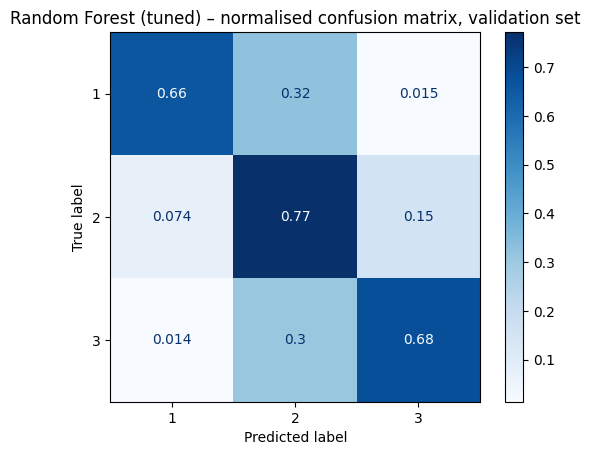

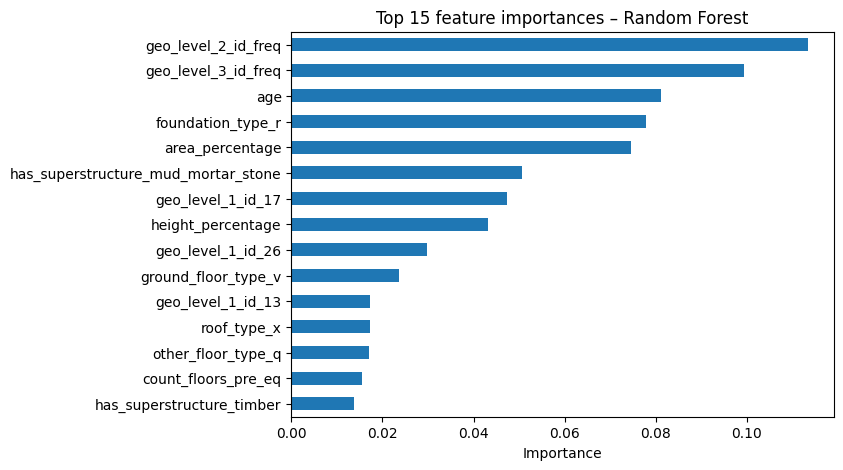

In [ ]:

# ===================== 8. PLOTS =====================
ConfusionMatrixDisplay.from_predictions(y_val, pred_best, normalize="true", cmap="Blues")
plt.title("Random Forest confusion matrix")
plt.savefig("rf_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

imp = pd.Series(rf_best.feature_importances_, index=names).sort_values()
imp.tail(15).plot(kind="barh", figsize=(7, 5), title="Top 15 feature importances – Random Forest")
plt.xlabel("Importance")
plt.savefig("rf_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# ===================== 9. FINAL TEST SCORE (run ONCE, after all tuning) =====================
pred_test = rf_best.predict(Xte)
report("RF tuned (TEST)", y_test, pred_test)


--- RF tuned (TEST) ---
Accuracy : 0.7286
Micro F1 : 0.7286
Macro F1 : 0.691
              precision    recall  f1-score   support

           1      0.575     0.645     0.608      3769
           2      0.763     0.774     0.768     22239
           3      0.718     0.676     0.697     13083

    accuracy                          0.729     39091
   macro avg      0.685     0.698     0.691     39091
weighted avg      0.730     0.729     0.729     39091

